# Dependencies

In [1]:
import warnings
warnings.simplefilter("ignore", UserWarning)

In [2]:
import sys
sys.path.append('../')

%load_ext autoreload
%autoreload 2

from libs import ios
from libs import vis
from libs.bibs import aps
from libs.inference import categorical
from libs.inference import numeric

# Setup

In [3]:
VERSION = 3
FN_PY_INF = f'../../results/v{VERSION}/gender/predictions_py/uniqueChineseAllGivenNames_PYgender_reg_mean_894_class_mean_607_1.csv'
FN_APS = '/data/datasets/APS/aps_data_processing/shares/aps-2022_25-10-01_e59319256d553035c40188457bb16edbfe02da04.zip'
FN_APS_OA_DEMOGRAPHICS = '/data/datasets/APS/aps_data_processing/shares/aps_20240130_2e52fdd7260ea462878821948a2a463ed9acb58a_20250120_APSOpenAlex/final_dataset.tar.gz'

PINYIN_OTHERS_DIR = f'../../results/v{VERSION}/gender/predictions_py_others/'
FN_PY_OTHERS = f'{PINYIN_OTHERS_DIR}/<OTHER_PROVIDER>/aps_pinyin_given_names_gendered.csv'
FN_PY_CLAUDE = FN_PY_OTHERS.replace('<OTHER_PROVIDER>', 'claude')
FN_PY_NAMSOR = FN_PY_OTHERS.replace('<OTHER_PROVIDER>', 'namsor')

PLOT_DIR = f'../../results/v{VERSION}/gender/predictions_py/plots'
ios.validate_path(PLOT_DIR)

In [4]:
vis.sns_paper_style()

# Data

## Ours

In [5]:
df_py = ios.load_csv(FN_PY_INF)
df_py.rename(columns={'givenname': 'ch_givenname', 'english_one':'py_givenname', 'pred':'ch_pred', 'pred_label':'ch_pred_label'}, inplace=True)
df_py.rename(columns={c:f"py_{c}" for c in df_py.columns if c.startswith('gender_')}, inplace=True)
df_py.loc[:, 'py_gender_mv'] = df_py.apply(lambda row: categorical.infer_gender_by_majority_vote(row['male_label_count'], row['female_label_count'], row['neutral_label_count']), axis=1)
df_py.shape


(46144, 19)

In [6]:
df_py.sample(5)

,ch_givenname,ch_pred,ch_pred_label,pop_CNKI,pop_NU,NLen,py_givenname,unique_name_count,py_gender_weighted_pop_CNKI,py_gender_weighted_pop_NU,py_gender_avg_all,py_gender_avg_CNKI,male_label_count,female_label_count,neutral_label_count,pop_sum_CNKI,pop_sum_NU,givennames,py_gender_mv
37332,积鉴,0.199827,male,1,99.971777,2,jijian,3,0.174571,0.164370,0.174571,0.174571,3,0,0,3,9278.135125,积鉴#继健#继建,male
19967,宏刚,0.202828,male,5,4079.374267,2,honggang,4,0.196079,0.195148,0.196777,0.196777,4,0,0,15,19218.911948,宏刚#宏岗#洪刚#红刚,male
7734,鸥,0.526585,neutral,3,35.762074,1,ou,13,0.426999,0.445951,0.401587,0.451895,7,0,6,9,85.110355,偶#呕#怄#欧#殴#沤#瓯#耦#藕#讴#鸥#𠙶#𬉼,male
24042,德柱,0.202828,male,1,3243.890157,2,dezhu,1,0.202828,0.202828,0.202828,0.202828,1,0,0,1,3243.890157,德柱,male
24966,怡文,0.538250,neutral,1,8771.027813,2,yiwen,14,0.368967,0.383016,0.410726,0.410726,6,2,6,24,48069.807938,一文#亦文#仪文#忆文#怡文#怡闻#怡雯#益文#羿文#艺文#译文#轶文#逸文#逸雯,male


In [7]:
cols_py = ['ch_givenname','py_givenname','ch_pred', 'py_gender_weighted_pop_CNKI', 'py_gender_weighted_pop_NU', 'py_gender_avg_all', 'py_gender_avg_CNKI', 'ch_pred_label', 'py_gender_mv']
df_py[cols_py].head(1)

,ch_givenname,py_givenname,ch_pred,py_gender_weighted_pop_CNKI,py_gender_weighted_pop_NU,py_gender_avg_all,py_gender_avg_CNKI,ch_pred_label,py_gender_mv
0,㑇,zhou,0.347726,0.281119,0.279068,0.333601,0.280243,male,male


## APS (Karimi and van Buskirk)

In [ ]:
_df_aps_authors = ios.read_csv_from_zip(FN_APS, 'data/authors.csv')
_df_aps_authors_names = ios.read_csv_from_zip(FN_APS, 'data/author_names.csv')
_df_aps_genders = ios.read_csv_from_zip(FN_APS, 'data/genders.csv')

df_aps = ios.pd.merge(_df_aps_authors, _df_aps_authors_names, how='inner', on='id_author', suffixes=("_a","_n"))
df_aps = ios.pd.merge(df_aps, _df_aps_genders, how='left', on='id_gender')
df_aps = df_aps[['id_author','id_author_name','name','gender','gender_nq', 'disambiguated']] # NOTE: it contains disambiguated True and False

print(f"APS authors: {_df_aps_authors.shape}")
print(f"APS authors names: {_df_aps_authors_names.shape}")
print(f"APS genders: {_df_aps_genders.shape}")
print(f"APS all authors merged: {df_aps.shape}")

df_aps_clean = aps.clean_aps_names(df_aps)
df_aps_clean_ch_py = aps.detect_pinyin_and_chinese_names(df_aps_clean)
print(f"APS clean ch-py: {df_aps_clean_ch_py.shape} (has_py_ch: {df_aps_clean_ch_py.has_py_ch.value_counts()})")

# APS authors: (874556, 4)
# APS authors names: (948771, 4)
# APS genders: (3, 2)
# APS all authors merged: (948771, 6)
# APS clean ch-py: (874556, 15) (has_py_ch: has_py_ch
# True     2636
# False    1086
# Name: count, dtype: int64)


APS authors: (874556, 4)
APS authors names: (948771, 4)
APS genders: (3, 2)
APS all authors merged: (948771, 6)


In [ ]:
df_aps_ch = df_aps_clean_ch_py.query('has_py_ch == True').copy()
df_aps_ch.rename(columns={'gender_clean': 'py_gender_karimi', 'gender_nq_clean': 'py_gender_buskirk'}, inplace=True)
df_aps_ch.loc[:,'py_gender_buskirk'] = df_aps_ch.loc[:,'py_gender_buskirk'].replace({'gm': 'male', 'gf': 'female'})
df_aps_ch.shape
# (2636, 15)

(2636, 15)

In [ ]:
df_aps_ch.head(1)

,id_author,alternative_names,n_alternative_names,genders,genders_nq,py_gender_karimi,py_gender_buskirk,longest_name,longest_name_clean,py_givenname_original,py_givenname,py_familyname,ch_givenname,ch_familyname,has_py_ch
294,294,"[Y. Liu, Y. Q. Liu, Y. Liu (刘育), Y. L. Liu, Y....",5,"[male, male, male, male, male]","[-, -, -, -, -]",male,unknown,Y. Liu (刘泱杰),y. liu,y.,yangjie,liu,泱杰,刘,True


In [ ]:
cols_aps = ['id_author','ch_givenname','py_givenname_original','py_givenname','py_gender_karimi','py_gender_buskirk']
df_aps_ch[cols_aps]

,id_author,ch_givenname,py_givenname_original,py_givenname,py_gender_karimi,py_gender_buskirk
294,294,泱杰,y.,yangjie,male,unknown
301,301,育,yu,yu,male,unknown
323,323,云旗,yunqi,yunqi,male,unknown
390,390,永好,yonghao,yonghao,male,unknown
429,429,玉敏,yumin,yumin,male,unknown
...,...,...,...,...,...,...
867994,867994,万兵,w. b.,wanbing,unknown,unknown
867995,867995,余刚,y. g.,yugang,unknown,unknown
867996,867996,喜光,x. g.,xiguang,unknown,unknown
867997,867997,翔舟,x. z.,xiangzhou,unknown,unknown


In [ ]:
df_aps_ch_unique_py = df_aps_ch.drop_duplicates(subset=['py_givenname','py_givenname_original'])

# Check how many reconstructed pinyin names match original pinyin names
# IF they don't match it means the original name is an initial; so unfair comparison with othe rmodels as we use the full reconstructed pinyin.
stats_pinyin_names_reconstructed = df_aps_ch_unique_py.apply(lambda row: row.py_givenname_original == row.py_givenname, axis=1).value_counts()
print(f"Reconstructed pinyin names match original pinyin names: \n{stats_pinyin_names_reconstructed}")

stats_pinyin_names_reconstructed /= stats_pinyin_names_reconstructed.sum()
print(f"\nReconstructed pinyin names match original pinyin names (proportion): \n{(stats_pinyin_names_reconstructed*100).round(2)}%")

# Keep only rows where reconstructed pinyin names match original pinyin names
df_aps_ch_unique_py_final = df_aps_ch_unique_py[df_aps_ch_unique_py.apply(lambda row: row.py_givenname_original == row.py_givenname, axis=1)].copy()
print(f"\nAfter keeping only rows where reconstructed pinyin names match original pinyin names: {df_aps_ch_unique_py_final.shape}")

tmp = df_aps_ch_unique_py_final[['py_givenname']].drop_duplicates()
fn = ios.path_join(PINYIN_OTHERS_DIR, f'aps_pinyin_given_names.csv')
ios.to_csv(tmp, fn)
print(f"Saved {tmp.shape[0]} unique APS pinyin given names to: {fn}")

# Reconstructed pinyin names match original pinyin names: 
# True     672
# False    584
# Name: count, dtype: int64

# Reconstructed pinyin names match original pinyin names (proportion): 
# True     53.5
# False    46.5
# Name: count, dtype: float64%

# After keeping only rows where reconstructed pinyin names match original pinyin names: (672, 15)
# Saved 672 unique APS pinyin given names to: ../../results/v3/gender/predictions_py_others/aps_pinyin_given_names.csv

Reconstructed pinyin names match original pinyin names: 
True     672
False    584
Name: count, dtype: int64

Reconstructed pinyin names match original pinyin names (proportion): 
True     53.5
False    46.5
Name: count, dtype: float64%

After keeping only rows where reconstructed pinyin names match original pinyin names: (672, 15)
Saved 672 unique APS pinyin given names to: ../../results/v3/gender/predictions_py_others/aps_pinyin_given_names.csv


## APS (Others)

In [ ]:
df_aps_py_claude = ios.load_csv(FN_PY_CLAUDE, index_col=0)
df_aps_py_namsor = ios.load_csv(FN_PY_NAMSOR, index_col=0)
df_aps_py_namsor.rename(columns={'likelyGender': 'py_gender_namsor'}, inplace=True)

df_aps_py_claude.py_givenname = df_aps_py_claude.py_givenname.astype(str)
df_aps_py_namsor.py_givenname = df_aps_py_namsor.py_givenname.astype(str)
df_aps_ch_unique_py_final.py_givenname = df_aps_ch_unique_py_final.py_givenname.astype(str)

df_aps_py_claude.set_index('py_givenname', inplace=True)
df_aps_py_namsor.set_index('py_givenname', inplace=True)

df_aps_py_claude.shape, df_aps_py_namsor.shape
# ((672, 1), (672, 9))

((672, 1), (672, 9))

In [ ]:
import gender_guesser.detector as guesser
detector = guesser.Detector()

In [ ]:
# appending predictions from other models to the APS unique pinyin given names dataframe
df_aps_ch_unique_py_final.loc[:,'py_gender_saeta'] = df_aps_ch_unique_py_final.py_givenname.apply(lambda n: detector.get_gender(n))
df_aps_ch_unique_py_final.loc[:,'py_gender_saeta_c'] = df_aps_ch_unique_py_final.py_givenname.apply(lambda n: detector.get_gender(n, country='china'))
df_aps_ch_unique_py_final = df_aps_ch_unique_py_final.merge(df_aps_py_claude, how='left', left_on='py_givenname', right_index=True)
df_aps_ch_unique_py_final = df_aps_ch_unique_py_final.merge(df_aps_py_namsor[['py_gender_namsor']], how='left', left_on='py_givenname', right_index=True)
df_aps_ch_unique_py_final.head(2)

,id_author,alternative_names,n_alternative_names,genders,genders_nq,py_gender_karimi,py_gender_buskirk,longest_name,longest_name_clean,py_givenname_original,py_givenname,py_familyname,ch_givenname,ch_familyname,has_py_ch,py_gender_saeta,py_gender_saeta_c,py_gender_claude,py_gender_namsor
301,301,"[Yu Liu (刘育), Yu Liu]",2,"[male, male]","[-, -]",male,unknown,Yu Liu (刘育),yu liu,yu,yu,liu,育,刘,True,unknown,unknown,neutral,female
323,323,"[Yunqi Liu, Yunqi Liu (刘云旗)]",2,"[male, male]","[-, -]",male,unknown,Yunqi Liu (刘云旗),yunqi liu,yunqi,yunqi,liu,云旗,刘,True,unknown,unknown,neutral,female


In [ ]:
df_aps_ch_unique_py_final.py_gender_saeta.unique(), df_aps_ch_unique_py_final.py_gender_saeta_c.unique(), df_aps_ch_unique_py_final.py_gender_namsor.unique(), df_aps_ch_unique_py_final.py_gender_claude.unique()  

(array(['unknown'], dtype=object),
 array(['unknown'], dtype=object),
 array(['female', 'male'], dtype=object),
 array(['neutral', 'male', 'female', 'unknown'], dtype=object))

# Comparison

In [ ]:
py_givenname_columns = ['py_givenname', 'py_givenname_original']
py_givenname_col = py_givenname_columns[0]
prefix = "no_initials" if py_givenname_col == 'py_givenname_original' else None
py_givenname_col, prefix

('py_givenname', None)

In [ ]:
# Aggregate APS data by Chinese given name: per chinese name, show pinyin and aggregated gender (for other methods).
df_aps_ch_agg = (
    df_aps_ch_unique_py_final
    .groupby(["ch_givenname", py_givenname_col], as_index=False)
    .agg({col: categorical.aggregate_gender for col in ["py_gender_karimi", "py_gender_buskirk", "py_gender_saeta", 'py_gender_claude', 'py_gender_namsor']})
)
df_aps_ch_agg.rename(columns={py_givenname_col: 'py_givenname'}, inplace=True)
df_aps_ch_agg = df_aps_ch_agg.groupby(["ch_givenname"]).filter(lambda x: x.py_givenname.nunique() == 1).copy()
df_aps_ch_agg
# 804 rows × 7 columns

,ch_givenname,py_givenname,py_gender_karimi,py_gender_buskirk,py_gender_saeta,py_gender_claude,py_gender_namsor
0,一君,yijun,male,unknown,unknown,male,male
1,一周,yizhou,male,unknown,unknown,male,male
2,一斐,yi fei,unknown,unknown,unknown,neutral,male
3,一昕,yixin,female,unknown,unknown,neutral,female
4,一洲,yizhou,male,unknown,unknown,male,male
...,...,...,...,...,...,...,...
815,鹏科,pengke,male,unknown,unknown,male,male
816,鹏程,pengcheng,unknown,unknown,unknown,male,male
817,黎,li,male,male,unknown,neutral,female
818,龙,long,male,unknown,unknown,male,male


In [ ]:
assert df_py.ch_givenname.nunique() == df_py.shape[0]
assert df_aps_ch_agg.ch_givenname.nunique() == df_aps_ch_agg.shape[0]

In [ ]:
df_py_genders = df_py.set_index('ch_givenname').join(df_aps_ch_agg.set_index('ch_givenname'), how='inner', lsuffix='_ours', rsuffix='_aps')
df_py_genders.shape
# (681, 24)

(681, 24)

In [ ]:
# original pinyin given name column comes from the original data, so names are not cleaned and may contain initials (e.g., "X.").
if py_givenname_col == 'py_givenname_original':
    df_py_genders = df_py_genders[~df_py_genders.py_givenname_karimi.str.contains(r"\.")].copy()
    df_py_genders = df_py_genders[df_py_genders.py_givenname_saeta.notna()].copy()
    print(df_py_genders.shape)

In [ ]:
cols = ['py_givenname_ours',
        'ch_pred','ch_pred_label','py_gender_mv',
        'py_gender_weighted_pop_CNKI','py_gender_weighted_pop_NU','py_gender_avg_all','py_gender_avg_CNKI',
        'py_givenname_aps',
        'py_gender_karimi','py_gender_buskirk','py_gender_saeta','py_gender_claude','py_gender_namsor'
        ]
df_py_genders[cols].head(5)

,py_givenname_ours,ch_pred,ch_pred_label,py_gender_mv,py_gender_weighted_pop_CNKI,py_gender_weighted_pop_NU,py_gender_avg_all,py_gender_avg_CNKI,py_givenname_aps,py_gender_karimi,py_gender_buskirk,py_gender_saeta,py_gender_claude,py_gender_namsor
ch_givenname,,,,,,,,,,,,,,
丁,ding,0.377206,neutral,male,0.334414,0.338034,0.356946,0.360417,ding,male,unknown,unknown,male,male
业,ye,0.324929,neutral,male,0.426069,0.453970,0.395760,0.447648,ye,male,unknown,unknown,neutral,female
东,dong,0.272237,male,male,0.336049,0.349730,0.334870,0.332124,dong,male,unknown,unknown,male,male
丹,dan,0.640028,female,male,0.630809,0.629659,0.394949,0.524874,dan,male,unknown,unknown,female,female
为,wei,0.256074,male,male,0.326056,0.311796,0.373857,0.395385,wei,male,unknown,unknown,neutral,male


In [ ]:
METHOD_LABELS = {
        "py_gender_karimi": "Karimi et al. (2016)",
        'py_gender_saeta': 'Saeta (2016)',
        "py_gender_buskirk": "van Buskirk et al. (2023)",
        "py_gender_claude": "Claude Opus 4.6",
        "py_gender_namsor": "Namsor (Genderize Name Geo)",
        "py_gender_mv": "Ours (PY)",
        "ch_pred_label": "Ours (CH)"
    }

METHOD_LABELS_SHORT = {
        "py_gender_karimi": "Kar.",
        'py_gender_saeta': "Sae.",
        "py_gender_buskirk": "vBu.",
        "py_gender_claude": "Cla.",
        "py_gender_namsor": "Nam.",
        "py_gender_mv": "(PY)",
        "ch_pred_label": "(CH)"
    }

METHOD_ORDER = ['py_gender_karimi', 'py_gender_saeta',"py_gender_buskirk", 'py_gender_claude', 'py_gender_namsor', 'py_gender_mv', 'ch_pred_label']

COLOR_METHODS = {'py_gender_karimi': "#1f77b4", 
                 'py_gender_buskirk': "#ff7f0e", 
                 'py_gender_saeta': "#2ca02c", 
                 'py_gender_claude': "#d62728",
                 'py_gender_namsor': "#9467bd",
                 'py_gender_mv': "#b7b7b7", 
                 'ch_pred_label': "#000000"}

HATCH_METHODS = {'py_gender_karimi': None, #'|',
                 'py_gender_buskirk': None, #'/',
                 'py_gender_saeta': None, #'-',
                 'py_gender_namsor': None, #'x',
                 'py_gender_claude': None, #'\\',
                 'py_gender_mv': '.', #'.',
                 'ch_pred_label': None, # 'o'
                 }


PINYIN_AGG_LABELS = {'py_gender_avg_all': 'Mean (all chars)', 
                     'py_gender_weighted_pop_NU': 'Weighted pop.', 
                     'py_gender_avg_CNKI': 'Mean (CNKI chars)', 
                     'py_gender_weighted_pop_CNKI': 'Weighted CNKI pop.'}

========== py_gender_avg_all ==========


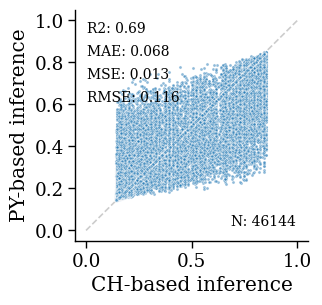

========== py_gender_weighted_pop_NU ==========


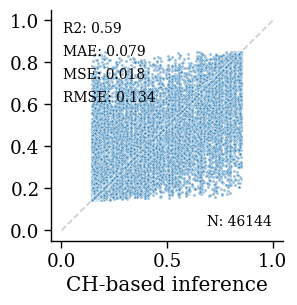

========== py_gender_avg_CNKI ==========


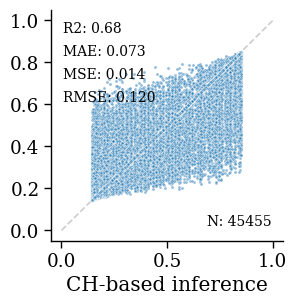

========== py_gender_weighted_pop_CNKI ==========


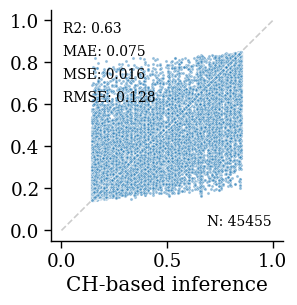

In [ ]:
rmse_pred_py_test = None

for col, label in PINYIN_AGG_LABELS.items():

    print(f"========== {col} ==========")

    df = df_py.dropna(subset=[col])
    
    mae_pred, mse_pred, rmse_pred, r2_pred = numeric.get_performance(df, 'ch_pred', col)
    performance_py = {'mae': mae_pred, 'mse': mse_pred, 'rmse': rmse_pred, 'r2': r2_pred}

    postfix = f"_{prefix}" if prefix is not None else ""
    fn = ios.path_join(PLOT_DIR, f'{col}_vs_ch_gender{postfix}.pdf')
    _, _ = vis.plot_regression_performance(df, 'ch_pred', col, 
                                    metrics = performance_py,
                                    figsize=(3, 3), 
                                    title=None, #f"Gender score (regression) from Pinyin",
                                    xlabel="CH-based inference", 
                                    ylabel="PY-based inference" if col == 'py_gender_avg_all' else None,
                                    markersize=5,
                                    markeralpha=0.5,
                                    fn=fn,
                                    )
    vis.plt.show()
    vis.plt.close()


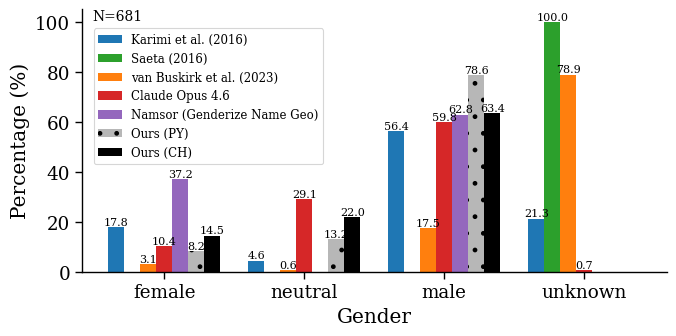

../../results/v3/gender/predictions_py/plots/py_gender_baseline_comparison.pdf


In [ ]:
from matplotlib import hatch


postfix = f"_{prefix}" if prefix is not None else ""
fn = f'{PLOT_DIR}/py_gender_baseline_comparison{postfix}.pdf'

fig, ax = vis.plot_gender_comparison(
    df_py_genders,
    method_order=METHOD_ORDER,
    method_labels=METHOD_LABELS,
    xlabel_order=['female', 'neutral', 'male', 'unknown'],
    colors = COLOR_METHODS,
    hatches = HATCH_METHODS,
    use_percentages=True,
    annotate_bars=True,
    title=None,
    fn = fn,
    n_annotation_kwargs={"fontsize": 10, "x": 0.06, "y":1.0, "ha": "center"} ,
    legend_kwargs={"loc": "upper left", "bbox_to_anchor": (0.01, 0.95), 'fontsize': 8.5},
    figsize=(7, 3.6),
)
vis.plt.show()
vis.plt.close()
print(fn)

In [ ]:

# 1) Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:
agreement_gt_ch = categorical.pairwise_agreement(df_py_genders, METHOD_ORDER)
print("Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:")
display(agreement_gt_ch.round(2))

# 2) Cohen's Kappa — agreement corrected for chance
kappa_gt_ch = categorical.pairwise_kappa(df_py_genders, METHOD_ORDER)
print("\nCohen's Kappa matrix (chance-corrected agreement):")
display(kappa_gt_ch.round(2))

Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:


,py_gender_karimi,py_gender_saeta,py_gender_buskirk,py_gender_claude,py_gender_namsor,py_gender_mv,ch_pred_label
py_gender_karimi,1.00,0.21,0.29,0.43,0.49,0.50,0.44
py_gender_saeta,0.21,1.00,0.79,0.01,0.00,0.00,0.00
py_gender_buskirk,0.29,0.79,1.00,0.14,0.15,0.17,0.14
py_gender_claude,0.43,0.01,0.14,1.00,0.62,0.65,0.70
py_gender_namsor,0.49,0.00,0.15,0.62,1.00,0.64,0.61
py_gender_mv,0.50,0.00,0.17,0.65,0.64,1.00,0.73
ch_pred_label,0.44,0.00,0.14,0.70,0.61,0.73,1.00



Cohen's Kappa matrix (chance-corrected agreement):


/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:730: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expected)


,py_gender_karimi,py_gender_saeta,py_gender_buskirk,py_gender_claude,py_gender_namsor,py_gender_mv,ch_pred_label
py_gender_karimi,1.00,0.0,0.03,0.09,0.11,0.07,0.08
py_gender_saeta,0.00,NaN,0.00,0.00,0.00,0.00,0.00
py_gender_buskirk,0.03,0.0,1.00,0.02,0.03,0.03,0.02
py_gender_claude,0.09,0.0,0.02,1.00,0.36,0.27,0.45
py_gender_namsor,0.11,0.0,0.03,0.36,1.00,0.24,0.29
py_gender_mv,0.07,0.0,0.03,0.27,0.24,1.00,0.41
ch_pred_label,0.08,0.0,0.02,0.45,0.29,0.41,1.00


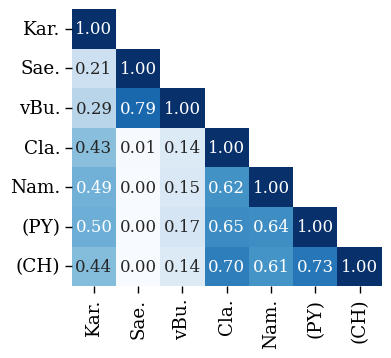

../../results/v3/gender/predictions_py/plots/py_gender_pairwise_agreement.pdf


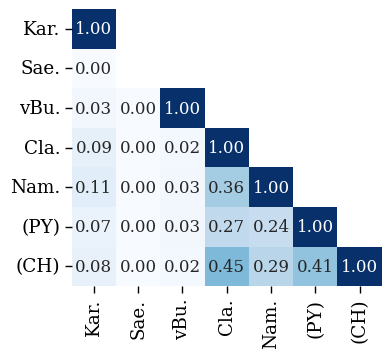

../../results/v3/gender/predictions_py/plots/py_gender_pairwise_kappa.pdf


In [ ]:

for kind, arr in {'agreement':agreement_gt_ch,'kappa':kappa_gt_ch}.items():
    arr = arr.to_numpy()
    arr[numeric.np.triu_indices(arr.shape[0], k=1)] = numeric.np.nan
    postfix = f"_{prefix}" if prefix is not None else ""
    fn = f'{PLOT_DIR}/py_gender_pairwise_{kind}{postfix}.pdf'
    vis.plot_confusion_matrix(arr, [METHOD_LABELS_SHORT[m] for m in METHOD_ORDER], 
                            title=None,
                            xlabel=None,
                            ylabel=None,
                            cbar=False,
                            annot_kws={'fontsize': 12},
                            cmap='Blues', figsize=(4., 3.6),
                            fn=fn,
                            )
    print(fn)

___

# Du et al

In [ ]:
fn_2k = f'../../data/v{VERSION}/Du/total_2w.csv'
fn_9k = f'../../data/v{VERSION}/Du/total_9800.csv'

df_2k = ios.load_csv(fn_2k)
df_9k = ios.load_csv(fn_9k)

df_2k.head(1), df_9k.head(1)



In [ ]:
df_py_genders.head(2)

In [ ]:
# df_2k_clean = df_2k.groupby('pinyin').label.nunique().reset_index(name='counts').copy()

# df_2k_clean.loc[:, 'py_gender_2k'] = df_2k_clean.apply(lambda row: df_2k.query("pinyin == @row.pinyin").label.iloc[0] if row.counts == 1 else 0.5, axis=1)

# df_2k_clean.loc[:, 'py_gender_2k'] = df_2k_clean.py_gender_2k.map({'male': 1.0, 'neutral': 0.5, 'female': 0.0})

df_2k_clean[['pinyin', 'py_gender_2k']].head(10)

In [ ]:
df_9k

In [ ]:
df_9k.groupby('first_name').label.nunique().reset_index(name='counts').query('counts > 1')

In [ ]:
# df_9k_clean = df_9k.groupby('first_name').label.nunique().reset_index(name='counts').copy()

# df_9k_clean.loc[:, 'py_gender_9k'] = df_9k_clean.apply(lambda row: df_9k.query("first_name == @row.first_name").label.iloc[0] if row.counts == 1 else 0.5, axis=1)

# df_9k_clean.loc[:, 'py_gender_9k'] = df_9k_clean.py_gender_9k.map({'male': 1.0, 'neutral': 0.5, 'female': 0.0})

df_9k_clean[['first_name', 'py_gender_9k']].head(20)

In [ ]:
n2k = df_2k.shape[0]
n2k_un = df_2k.groupby('pinyin').filter(lambda x: x.label.nunique() > 1).groupby('pinyin')[['label']].value_counts().reset_index(name='count').shape[0]

n2k, n2k_un

In [ ]:
n9k = df_9k.shape[0]
n9k_un = df_9k.groupby('first_name').filter(lambda x: x.label.nunique() > 1).groupby('first_name')[['label']].value_counts().reset_index(name='count').shape[0]
n9k, n9k_un
